# Predicting Income Level from Census Data
**Project 3 — Machine Learning Foundations**

## 1. Problem Definition

**Task type:** Supervised learning — **binary classification**.

**Goal:** Predict whether a person's annual income is **above \$50K** (`>50K`) or **at or below \$50K** (`<=50K`) from demographic and employment attributes recorded in the 1994 U.S. Census.

**Dataset:** *Adult* (also known as "Census Income"), UCI Machine Learning Repository — https://archive.ics.uci.edu/dataset/2/adult (Becker & Kohavi, 1996).
The original `adult.data` (train) and `adult.test` files were combined into a single `adult.csv` with a header row; no values were altered.

**Why this framing:** the target is a clearly defined categorical label, the classes are imbalanced (which makes metric selection meaningful), and the data contains sensitive attributes (sex, race) that allow us to examine model fairness.

## 2. Setup
Import libraries and fix a random seed so results are reproducible.

In [2]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42  # used everywhere randomness is involved, for reproducibility

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

numpy 2.5.5 | pandas 3.1.1 | scikit-learn 1.9.1


## 3. Load and Inspect the Dataset

In [3]:
# Load the raw CSV. skipinitialspace guards against stray spaces after commas.
df = pd.read_csv("adult.csv", skipinitialspace=True)

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 48,842 rows x 15 columns


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


### 3.1 Column names and data types

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      48842 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48842 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [5]:
# Split columns by type — this drives preprocessing later
TARGET = "income"
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in df.select_dtypes(exclude="number").columns if c != TARGET]

print("Numeric features    :", numeric_cols)
print("Categorical features:", categorical_cols)
print("Target              :", TARGET)

Numeric features    : ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Target              : income


In [6]:
# Summary statistics for numeric features
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


### 3.2 Data quality checks

In [7]:
# 1) Missing values: the UCI files encode "unknown" as '?', so pandas does not see them as NaN
question_marks = (df == "?").sum()
print("Cells containing '?':")
print(question_marks[question_marks > 0])
print(f"\nRows with at least one '?': {(df == '?').any(axis=1).sum():,} "
      f"({(df == '?').any(axis=1).mean():.1%} of rows)")
print(f"True NaN values: {df.isna().sum().sum()}")

Cells containing '?':
workclass         2799
occupation        2809
native-country     857
dtype: int64

Rows with at least one '?': 3,620 (7.4% of rows)
True NaN values: 0


In [8]:
# 2) Inconsistent target labels: the test file adds a trailing period ('>50K.')
df[TARGET].value_counts()

income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64

In [9]:
# 3) Exact duplicate rows
print(f"Duplicate rows: {df.duplicated().sum():,}")

Duplicate rows: 29


In [10]:
# 4) Skewed numeric features: capital gain / loss are zero for most people
for col in ["capital-gain", "capital-loss"]:
    print(f"{col}: {(df[col] == 0).mean():.1%} zeros, max = {df[col].max():,}")

capital-gain: 91.7% zeros, max = 99,999
capital-loss: 95.3% zeros, max = 4,356


In [11]:
# 5) Redundant columns: education (text) and education-num (ordinal code) carry the same information
codes_per_level = df.groupby("education")["education-num"].nunique()
print(f"Each education level maps to exactly one education-num code: {(codes_per_level == 1).all()}")
df.groupby("education")["education-num"].first().sort_values().to_frame().T

Each education level maps to exactly one education-num code: True


education,Preschool,1st-4th,5th-6th,7th-8th,9th,10th,11th,12th,HS-grad,Some-college,Assoc-voc,Assoc-acdm,Bachelors,Masters,Prof-school,Doctorate
education-num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16


### 3.3 Data quality notes

- **Hidden missing values.** Missing entries are stored as `'?'` in `workclass`, `occupation` and `native-country` (7.4% of rows affected), not as `NaN`. They must be converted before imputation.
- **Inconsistent labels.** The target has four spellings (`<=50K`, `<=50K.`, `>50K`, `>50K.`) because the original test file appends a period. These will be normalized to two classes.
- **Duplicates.** 29 exact duplicate rows exist (<0.1%). With no person identifier, they could be genuinely different people with identical attributes, so this is noted rather than assumed to be an error.
- **Skewed features.** `capital-gain` and `capital-loss` are zero for the vast majority of rows, with a long right tail; the maximum of 99,999 looks like a recording cap rather than a real value.
- **Redundancy.** `education` and `education-num` map one-to-one, so only one should be kept. `fnlwgt` is a census sampling weight rather than a personal attribute.

## 4. Data Cleaning

Fix the issues found in Section 3 that are *errors in the file*, not modelling choices:

1. Normalize the four target spellings to two classes and encode the target as `1 = >50K`, `0 = <=50K`.
2. Convert `'?'` to a real missing value (`NaN`) so that imputation can handle it inside the pipeline later.
3. Keep the 29 duplicate rows. With no person ID, identical rows may be different people, and removing 0.06% of the data has no material effect either way.

Missing values are **not** filled in here. Filling them before the train/test split would let information from the test set leak into training (Kaufman et al., 2012), so imputation happens inside the preprocessing pipeline in Section 6.

In [12]:
clean = df.copy()

# 1) Normalize target labels: strip the trailing '.' added in the original test file
clean[TARGET] = clean[TARGET].str.rstrip(".")
clean[TARGET] = (clean[TARGET] == ">50K").astype(int)   # 1 = >50K, 0 = <=50K

# 2) Turn '?' placeholders into proper missing values
clean = clean.replace("?", np.nan)

print("Target classes after cleaning:", sorted(clean[TARGET].unique()))
print("\nMissing values per column (now visible to pandas):")
print(clean.isna().sum()[lambda s: s > 0])

Target classes after cleaning: [np.int64(0), np.int64(1)]

Missing values per column (now visible to pandas):
workclass         2799
occupation        2809
native-country     857
dtype: int64


## 5. Exploratory Data Analysis
Figures are also saved to `figures/` for use in the report.

In [13]:
from pathlib import Path

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    """Save a figure to figures/<name>.png at report quality."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

### 5.1 Target balance

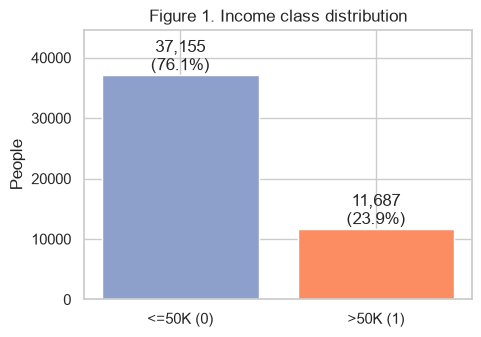

A model that always predicts '<=50K' would already be 76.1% accurate.


In [14]:
counts = clean[TARGET].value_counts().sort_index()
shares = counts / counts.sum()

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["<=50K (0)", ">50K (1)"], counts, color=["#8da0cb", "#fc8d62"])
for i, (n, p) in enumerate(zip(counts, shares)):
    ax.text(i, n, f"{n:,}\n({p:.1%})", ha="center", va="bottom")
ax.set_ylabel("People")
ax.set_title("Figure 1. Income class distribution")
ax.set_ylim(0, counts.max() * 1.2)
save(fig, "fig1_class_balance")
plt.show()

print(f"A model that always predicts '<=50K' would already be {shares[0]:.1%} accurate.")

The classes are imbalanced (about 3 to 1). Accuracy alone would therefore be a misleading measure, because a model that never predicts `>50K` still scores about 76%. Evaluation in Section 8 will focus on precision, recall, F1 and ROC-AUC instead.

### 5.2 Numeric features by income class

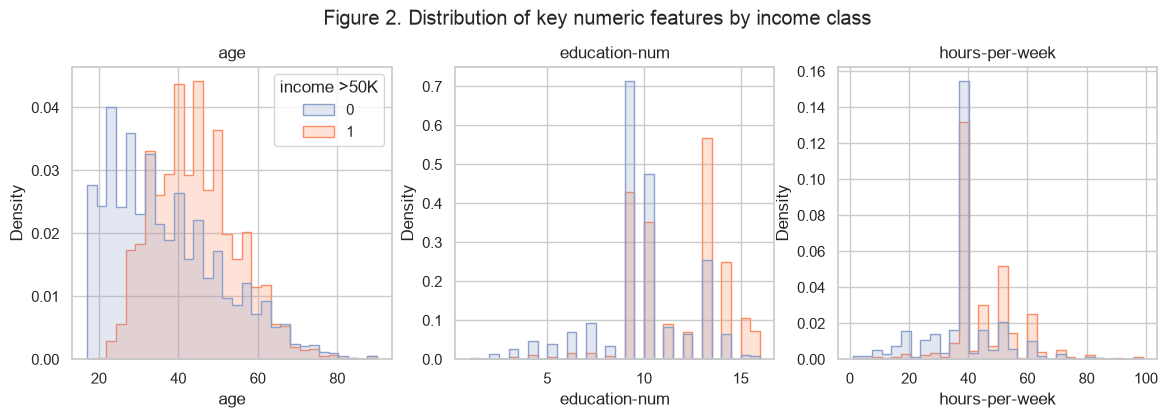

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
income,,,,,,
<=50K,36.9,190039.6,9.6,147.0,54.2,38.8
>50K,44.3,188470.6,11.6,4042.2,193.5,45.5


In [15]:
plot_cols = ["age", "education-num", "hours-per-week"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, plot_cols):
    sns.histplot(data=clean, x=col, hue=TARGET, stat="density", common_norm=False,
                 bins=30, element="step", ax=ax, palette=["#8da0cb", "#fc8d62"])
    ax.set_title(col)
axes[0].get_legend().set_title("income >50K")
for ax in axes[1:]:
    ax.get_legend().remove()
fig.suptitle("Figure 2. Distribution of key numeric features by income class", y=1.03)
save(fig, "fig2_numeric_by_class")
plt.show()

# Mean of each numeric feature per class, as a compact table
clean.groupby(TARGET)[numeric_cols].mean().round(1).rename(index={0: "<=50K", 1: ">50K"})

Higher earners are older on average, have more years of education, and work longer hours. All three features should be useful predictors.

### 5.3 Share of high earners across categories

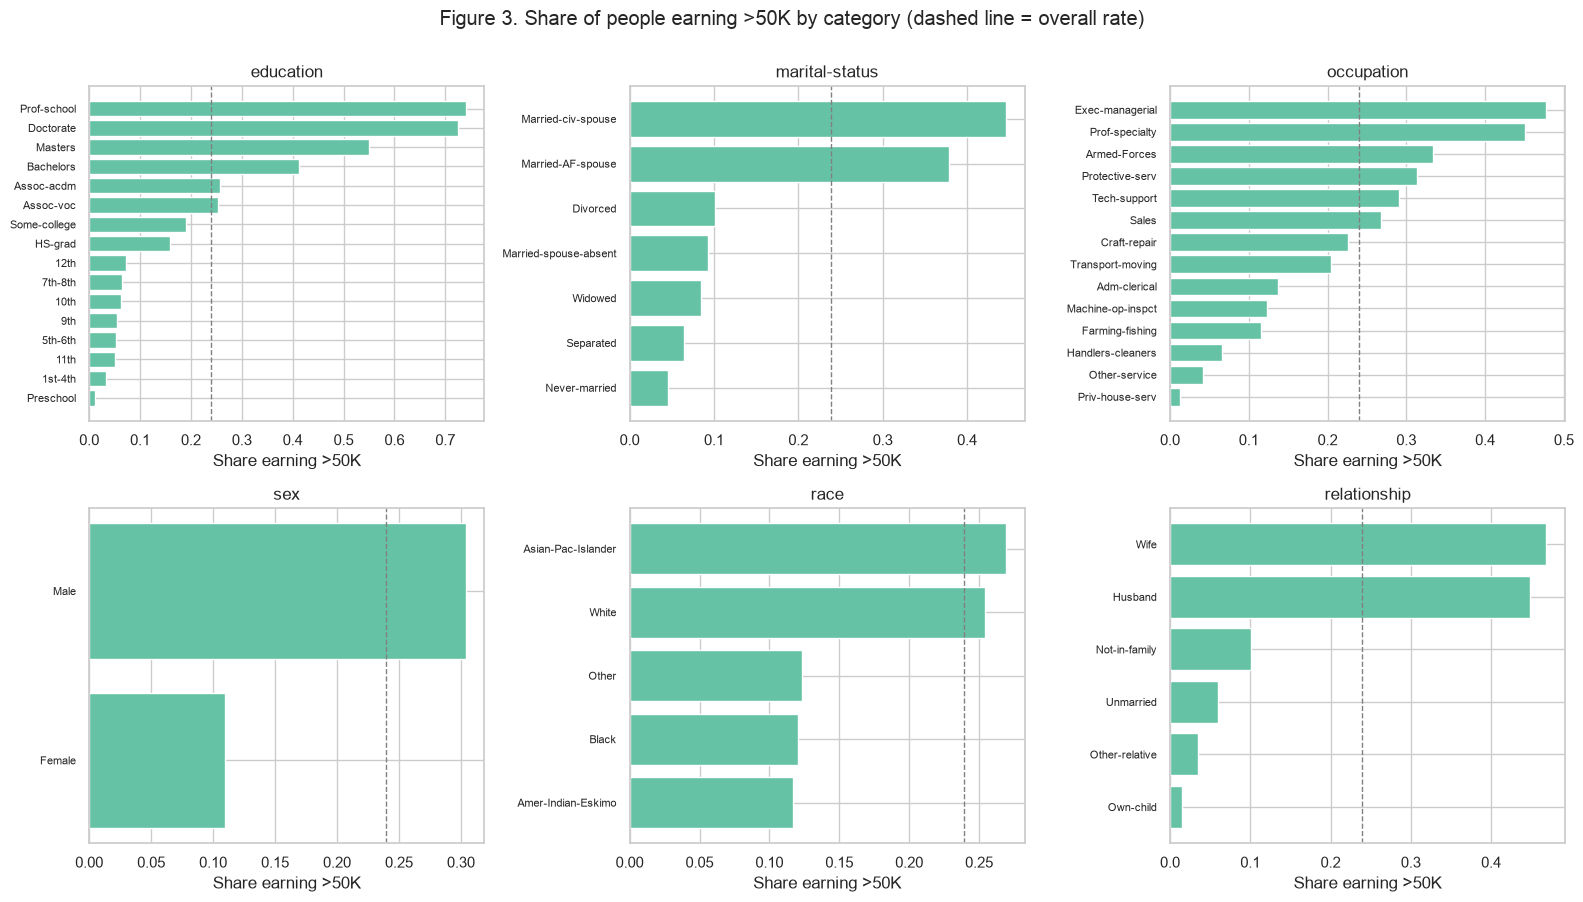

In [16]:
cat_plot_cols = ["education", "marital-status", "occupation", "sex", "race", "relationship"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
overall_rate = clean[TARGET].mean()
for ax, col in zip(axes.ravel(), cat_plot_cols):
    rate = clean.groupby(col)[TARGET].mean().sort_values()
    ax.barh(rate.index, rate.values, color="#66c2a5")
    ax.axvline(overall_rate, color="grey", ls="--", lw=1)
    ax.set_title(col)
    ax.set_xlabel("Share earning >50K")
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Figure 3. Share of people earning >50K by category (dashed line = overall rate)", y=1.0)
fig.tight_layout()
save(fig, "fig3_rate_by_category")
plt.show()

### 5.4 Sensitive attributes

In [17]:
# Group sizes and high-earner rates for the sensitive attributes we will audit later
for col in ["sex", "race"]:
    summary = clean.groupby(col)[TARGET].agg(count="size", share_over_50k="mean")
    summary["share_of_data"] = summary["count"] / len(clean)
    display(summary.sort_values("count", ascending=False).style.format(
        {"count": "{:,}", "share_over_50k": "{:.1%}", "share_of_data": "{:.1%}"}))

,count,share_over_50k,share_of_data
sex,,,
Male,"32,650",30.4%,66.8%
Female,"16,192",10.9%,33.2%


,count,share_over_50k,share_of_data
race,,,
White,"41,762",25.4%,85.5%
Black,"4,685",12.1%,9.6%
Asian-Pac-Islander,"1,519",26.9%,3.1%
Amer-Indian-Eskimo,470,11.7%,1.0%
Other,406,12.3%,0.8%


- Only about 11% of women in the data earn more than \$50K, compared with about 30% of men. Women make up only one third of the rows.
- About 85% of rows are labelled `White`. Groups such as `Amer-Indian-Eskimo` and `Other` have only a few hundred rows each, so any metric calculated for them will be noisy.
- `relationship` partly encodes sex (`Husband` / `Wife`), so removing the `sex` column alone would not stop the model from learning sex-related patterns.

These gaps reflect 1994 labour-market inequality recorded in the census. A model trained on this data can reproduce them, so Section 9 checks the model's errors separately for each group.

### 5.5 Correlation between numeric features

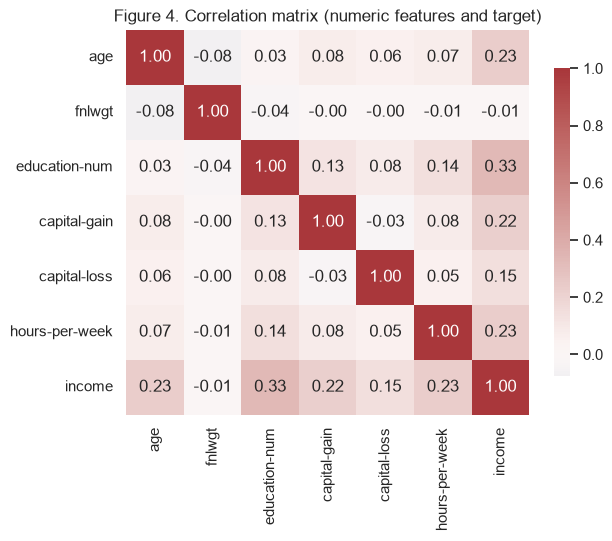

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 5))
corr = clean[numeric_cols + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Figure 4. Correlation matrix (numeric features and target)")
save(fig, "fig4_correlation")
plt.show()

No pair of numeric features is strongly correlated, so multicollinearity is not a concern for a linear model. `fnlwgt` has almost no correlation with the target, which matches its role as a census sampling weight rather than a personal attribute.

## 6. Preprocessing

### 6.1 Feature selection

| Decision | Reason |
|---|---|
| Drop `education` | Duplicates `education-num` one-to-one (Section 3.2). The ordinal number keeps the ordering of education levels. |
| Drop `fnlwgt` | A survey sampling weight that describes how the census sample was drawn, not the person (UCI `adult.names`). It has near-zero correlation with the target. |
| Keep `sex` and `race` as features for the main model | The data records them, and removing them alone does not remove their influence (see `relationship`). Section 9 audits fairness and compares against a model trained without them. |
| `log1p` transform on `capital-gain` and `capital-loss` | Over 90% zeros with a long right tail. The log compresses extreme values so they do not dominate a linear model. |

In [19]:
X = clean.drop(columns=[TARGET, "education", "fnlwgt"])
y = clean[TARGET]

num_features = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
log_features = ["capital-gain", "capital-loss"]          # subset of num_features to log-transform
cat_features = ["workclass", "marital-status", "occupation", "relationship",
                "race", "sex", "native-country"]
SENSITIVE = ["sex", "race"]

assert set(num_features + cat_features) == set(X.columns)
print(f"X: {X.shape[0]:,} rows x {X.shape[1]} features | positive rate = {y.mean():.1%}")

X: 48,842 rows x 12 features | positive rate = 23.9%


### 6.2 Train / test split

An 80/20 split, **stratified** on the target so that both sets keep the same 76/24 class ratio. The test set is held back and used only once, for final evaluation. Model tuning uses cross-validation on the training set only (Hastie et al., 2009).

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,} rows | positive rate {y_train.mean():.1%}")
print(f"Test : {len(X_test):,} rows | positive rate {y_test.mean():.1%}")

Train: 39,073 rows | positive rate 23.9%
Test : 9,769 rows | positive rate 23.9%


### 6.3 Preprocessing pipeline

All transformations are wrapped in a single scikit-learn `ColumnTransformer`. Inside cross-validation and on the test set, the imputers, scaler and encoder are **fitted on training data only**, which prevents data leakage (Pedregosa et al., 2011).

- **Numeric:** median imputation, then `log1p` for the two capital columns, then standardization (mean 0, std 1). Scaling matters for logistic regression, because the regularization penalty treats all coefficients on the same scale.
- **Categorical:** most-frequent imputation, then one-hot encoding. Categories seen fewer than 20 times in training (for example rare countries) are grouped into a single "infrequent" column, and categories never seen in training are ignored safely at prediction time.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

def build_preprocessor(num_cols, cat_cols, log_cols=()):
    """Return a ColumnTransformer that imputes, transforms and encodes the given columns."""
    plain_num = [c for c in num_cols if c not in log_cols]
    log_num = [c for c in num_cols if c in log_cols]

    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    skewed = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                 sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric, plain_num),
        ("log", skewed, log_num),
        ("cat", categorical, cat_cols),
    ])

preprocessor = build_preprocessor(num_features, cat_features, log_features)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('log', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [23]:
# Sanity check: fit on the training set only and inspect the result
X_train_prepared = preprocessor.fit_transform(X_train)
feature_names = preprocessor.get_feature_names_out()

print(f"Columns before: {X_train.shape[1]}  ->  after encoding: {X_train_prepared.shape[1]}")
print(f"Missing values after preprocessing: {np.isnan(X_train_prepared).sum()}")
pd.DataFrame(X_train_prepared, columns=feature_names, index=X_train.index).head()

Columns before: 12  ->  after encoding: 80
Missing values after preprocessing: 0


,num__age,num__education-num,num__hours-per-week,log__capital-gain,log__capital-loss,cat__workclass_Federal-gov,cat__workclass_Local-gov,cat__workclass_Private,cat__workclass_Self-emp-inc,cat__workclass_Self-emp-not-inc,cat__workclass_State-gov,cat__workclass_infrequent_sklearn,cat__marital-status_Divorced,cat__marital-status_Married-AF-spouse,cat__marital-status_Married-civ-spouse,cat__marital-status_Married-spouse-absent,cat__marital-status_Never-married,cat__marital-status_Separated,cat__marital-status_Widowed,cat__occupation_Adm-clerical,cat__occupation_Craft-repair,cat__occupation_Exec-managerial,cat__occupation_Farming-fishing,cat__occupation_Handlers-cleaners,cat__occupation_Machine-op-inspct,cat__occupation_Other-service,cat__occupation_Priv-house-serv,cat__occupation_Prof-specialty,cat__occupation_Protective-serv,cat__occupation_Sales,cat__occupation_Tech-support,cat__occupation_Transport-moving,cat__occupation_infrequent_sklearn,cat__relationship_Husband,cat__relationship_Not-in-family,cat__relationship_Other-relative,cat__relationship_Own-child,cat__relationship_Unmarried,cat__relationship_Wife,cat__race_Amer-Indian-Eskimo,cat__race_Asian-Pac-Islander,cat__race_Black,cat__race_Other,cat__race_White,cat__sex_Female,cat__sex_Male,cat__native-country_Cambodia,cat__native-country_Canada,cat__native-country_China,cat__native-country_Columbia,cat__native-country_Cuba,cat__native-country_Dominican-Republic,cat__native-country_Ecuador,cat__native-country_El-Salvador,cat__native-country_England,cat__native-country_France,cat__native-country_Germany,cat__native-country_Greece,cat__native-country_Guatemala,cat__native-country_Haiti,cat__native-country_Hong,cat__native-country_India,cat__native-country_Iran,cat__native-country_Ireland,cat__native-country_Italy,cat__native-country_Jamaica,cat__native-country_Japan,cat__native-country_Mexico,cat__native-country_Nicaragua,cat__native-country_Peru,cat__native-country_Philippines,cat__native-country_Poland,cat__native-country_Portugal,cat__native-country_Puerto-Rico,cat__native-country_South,cat__native-country_Taiwan,cat__native-country_Thailand,cat__native-country_United-States,cat__native-country_Vietnam,cat__native-country_infrequent_sklearn
34495,-0.120090,1.138210,-0.844835,-0.296054,-0.220527,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
18591,1.268245,-0.804025,-0.038454,-0.296054,4.466051,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
12562,1.049034,-0.415578,-0.441645,-0.296054,-0.220527,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
552,2.437369,-1.192472,-0.038454,-0.296054,-0.220527,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3479,0.537542,1.526657,-0.199731,-0.296054,-0.220527,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


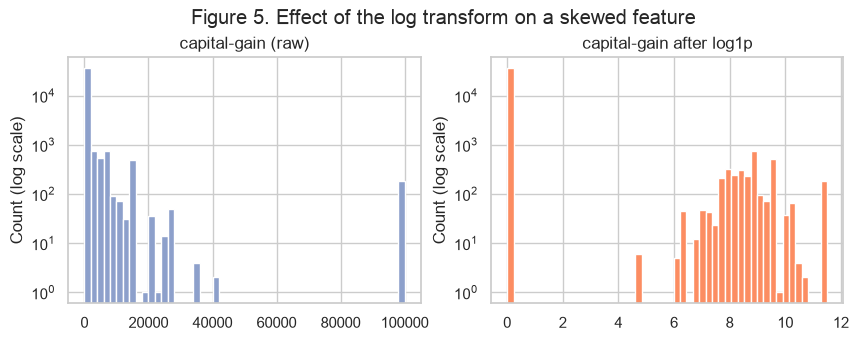

In [24]:
# Confirm the log transform tamed the skew of capital-gain
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(X_train["capital-gain"], bins=50, color="#8da0cb")
axes[0].set_title("capital-gain (raw)")
axes[1].hist(np.log1p(X_train["capital-gain"]), bins=50, color="#fc8d62")
axes[1].set_title("capital-gain after log1p")
for ax in axes:
    ax.set_yscale("log")
    ax.set_ylabel("Count (log scale)")
fig.suptitle("Figure 5. Effect of the log transform on a skewed feature", y=1.03)
save(fig, "fig5_log_transform")
plt.show()

### 6.4 Preprocessing summary

- 48,842 rows; the target is binary with 23.9% positives.
- Drop 2 columns (`education`, `fnlwgt`), leaving 12 input features: 5 numeric and 7 categorical. These become the one-hot encoded matrix shown above.
- Missing values are filled inside the pipeline using statistics learned from the training set only.
- The test set (20%, stratified) stays untouched until final evaluation.

*Next: model training and evaluation (Sections 7–8).*